# Multilayer Perceptron from Scratch (NumPy)

A fully-connected network with two hidden layers, built with only NumPy: forward pass, loss, backpropagation by hand, and plain stochastic gradient descent.

**Task:** predict tomorrow's temperature from today's morning, afternoon and evening readings.

**Architecture:** 3 → 16 (tanh) → 8 (tanh) → 1 (linear)

**Loss:** per-sample squared error. **Optimiser:** online SGD (one sample per update).

scikit-learn is used only for the train/test split, scaling and metrics. The model itself is pure NumPy.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

## 1.  Load Data

`temp_vanilla.csv` has 100 consecutive days of readings. The three inputs are `temp_morning`, `temp_afternoon` and `temp_evening`; the target is `next_day_temp`.

Each row is treated as an independent sample $\mathbf{x} \in \mathbb{R}^3$, $y \in \mathbb{R}$, so the network sees one day's three readings as a flat vector with no notion of order.

In [2]:
df = pd.read_csv("temp_vanilla.csv")

X = df[[
    "temp_morning",
    "temp_afternoon",
    "temp_evening"
]].values

y = df["next_day_temp"].values.reshape(-1, 1)

## 2.  Train / test split

The data is split 80/20 with a fixed `random_state`, giving 80 training and 20 test samples. The test set is touched only once, at the end.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print(X_train.shape)
print(y_train.shape)

(80, 3)
(80, 1)


## 3. Standard scaling

Inputs and targets are both standardised to zero mean and unit variance. The scalers are **fitted on the training data only** and merely applied to the test data, so no test statistics leak into training.

Predictions are later converted back to original temperature units with `y_scaler.inverse_transform` before computing the metrics.

In [4]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train)
X_test  = x_scaler.transform(X_test)

y_train       = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

## 4. Hyperparameters

| Symbol | Value | Meaning |
|---|---|---|
| $d$ | 3 | input features |
| $h_1$ | 16 | neurons in hidden layer 1 |
| $h_2$ | 8 | neurons in hidden layer 2 |
| $k$ | 1 | outputs |
| $\eta$ | 0.001 | learning rate |
| epochs | 1000 | full passes over the training set |

In [5]:
input_size    = 3   # d = 3   (morning, afternoon, evening)
hidden_size_1 = 16  # h1 = 16
hidden_size_2 = 8   # h2 = 8
output_size   = 1   # k  = 1

learning_rate = 0.001
epochs = 1000

## 5. Parameter initialisation

$$
W_1 \in \mathbb{R}^{16\times 3},\quad W_2 \in \mathbb{R}^{8\times 16},\quad W_3 \in \mathbb{R}^{1\times 8}
$$

with bias vectors $\mathbf{b}_1 \in \mathbb{R}^{16}$, $\mathbf{b}_2 \in \mathbb{R}^{8}$, $\mathbf{b}_3 \in \mathbb{R}^{1}$. That is $64 + 136 + 9 = 209$ parameters in total.

Weights are drawn as $0.1\times\mathcal{N}(0,1)$ (standard deviation 0.1) and biases start at zero. The small values keep the pre-activations near zero, so tanh starts in its near-linear region instead of saturating.

The parameters are stored in a dictionary so the functions below can read and update them. The seed line is commented out, so each run starts from different weights and the final metrics vary slightly.

In [6]:
# np.random.seed(42)

params = {
    # Layer 1 : input -> hidden 1
    "W1": np.random.randn(hidden_size_1, input_size) * 0.1,
    "b1": np.zeros((hidden_size_1, 1)),

    # Layer 2 : hidden 1 -> hidden 2
    "W2": np.random.randn(hidden_size_2, hidden_size_1) * 0.1,
    "b2": np.zeros((hidden_size_2, 1)),

    # Layer 3 : hidden 2 -> output (linear output for regression)
    "W3": np.random.randn(output_size, hidden_size_2) * 0.1,
    "b3": np.zeros((output_size, 1)),
}

## 6. Forward pass

For a single sample $\mathbf{x} \in \mathbb{R}^{3\times 1}$:

$$
\begin{aligned}
\mathbf{z}_1 &= W_1 \mathbf{x} + \mathbf{b}_1, & \mathbf{a}_1 &= \tanh(\mathbf{z}_1) \\
\mathbf{z}_2 &= W_2 \mathbf{a}_1 + \mathbf{b}_2, & \mathbf{a}_2 &= \tanh(\mathbf{z}_2) \\
\hat{y} &= W_3 \mathbf{a}_2 + \mathbf{b}_3
\end{aligned}
$$

tanh is used in the hidden layers because it is smooth and zero-centred. The output layer is **linear** because the target is a continuous, unbounded quantity.

The function returns $\mathbf{a}_1$, $\mathbf{a}_2$ and $\hat{y}$, since backpropagation needs the activations.

In [7]:
def forward(x, p):
    z1 = p["W1"] @ x + p["b1"]
    a1 = np.tanh(z1)

    z2 = p["W2"] @ a1 + p["b2"]
    a2 = np.tanh(z2)

    y_hat = p["W3"] @ a2 + p["b3"]   # linear output
    return a1, a2, y_hat

## 7. Loss function

Per-sample squared error:

$$
L = \tfrac{1}{2}\,\lVert \hat{y} - y \rVert^2
$$

The factor $\tfrac12$ cancels the 2 produced by differentiation, so $\dfrac{\partial L}{\partial \hat y} = \hat y - y$.

In [8]:
def compute_loss(y_hat, target):
    return 0.5 * np.sum((y_hat - target) ** 2)

## 8. Backpropagation

Backpropagation is the chain rule applied from the output back to the input. Using $\tanh'(z) = 1 - \tanh^2(z) = 1 - a^2$, and writing $\delta_\bullet = \partial L/\partial \bullet$:

**Output layer**

$$
\delta_y = \hat y - y,\qquad
\frac{\partial L}{\partial W_3} = \delta_y\,\mathbf{a}_2^\top,\qquad
\frac{\partial L}{\partial \mathbf{b}_3} = \delta_y
$$

**Hidden layer 2**

$$
\delta_{\mathbf{a}_2} = W_3^\top \delta_y,\qquad
\delta_{\mathbf{z}_2} = \delta_{\mathbf{a}_2}\odot(1-\mathbf{a}_2^2),\qquad
\frac{\partial L}{\partial W_2} = \delta_{\mathbf{z}_2}\,\mathbf{a}_1^\top,\qquad
\frac{\partial L}{\partial \mathbf{b}_2} = \delta_{\mathbf{z}_2}
$$

**Hidden layer 1**

$$
\delta_{\mathbf{a}_1} = W_2^\top \delta_{\mathbf{z}_2},\qquad
\delta_{\mathbf{z}_1} = \delta_{\mathbf{a}_1}\odot(1-\mathbf{a}_1^2),\qquad
\frac{\partial L}{\partial W_1} = \delta_{\mathbf{z}_1}\,\mathbf{x}^\top,\qquad
\frac{\partial L}{\partial \mathbf{b}_1} = \delta_{\mathbf{z}_1}
$$

Here $\odot$ is the element-wise (Hadamard) product. The pattern repeats at every layer: push the error back through the transposed weights, multiply element-wise by the local activation derivative, then form the weight gradient as an outer product with the layer's input.

In [9]:
def backward(x, a1, a2, y_hat, target, p):
    # Output layer gradient
    dy  = y_hat - target          # dL / d y_hat
    dW3 = dy @ a2.T
    db3 = dy

    # Hidden layer 2 gradient
    da2 = p["W3"].T @ dy
    dz2 = da2 * (1 - a2 ** 2)     # tanh'(z2) = 1 - a2^2
    dW2 = dz2 @ a1.T
    db2 = dz2

    # Hidden layer 1 gradient
    da1 = p["W2"].T @ dz2
    dz1 = da1 * (1 - a1 ** 2)     # tanh'(z1) = 1 - a1^2
    dW1 = dz1 @ x.T
    db1 = dz1

    return {"W1": dW1, "b1": db1,
            "W2": dW2, "b2": db2,
            "W3": dW3, "b3": db3}

## 9. Parameter update (gradient descent)

$$
W_i \leftarrow W_i - \eta\,\frac{\partial L}{\partial W_i},\qquad
\mathbf{b}_i \leftarrow \mathbf{b}_i - \eta\,\frac{\partial L}{\partial \mathbf{b}_i},\qquad i\in\{1,2,3\}
$$

The update runs after **every single training sample** (online SGD), so there are 80 updates per epoch. The arrays are modified in place.

In [10]:
def update(p, grads, lr):
    for name in p:
        p[name] -= lr * grads[name]

## 10. Training loop

For each epoch, every training sample goes through: forward pass → loss → backpropagation → update.

The printed loss is the mean per-sample loss $\tfrac12(\hat y - y)^2$ over the epoch, in **standardised** target units.

In [11]:
loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for n in range(len(X_train)):

        x = X_train[n].reshape(-1, 1)          # shape (d, 1)
        target = np.array([[y_train[n, 0]]])   # shape (k, 1)

        a1, a2, y_hat = forward(x, params)
        total_loss += compute_loss(y_hat, target)

        grads = backward(x, a1, a2, y_hat, target, params)
        update(params, grads, learning_rate)

    loss_history.append(total_loss)

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch:4d}   Loss = {total_loss / len(X_train):.6f}"
        )

Epoch    0   Loss = 0.486159
Epoch  100   Loss = 0.045591
Epoch  200   Loss = 0.045471
Epoch  300   Loss = 0.045366
Epoch  400   Loss = 0.045270
Epoch  500   Loss = 0.045180
Epoch  600   Loss = 0.045093
Epoch  700   Loss = 0.045009
Epoch  800   Loss = 0.044927
Epoch  900   Loss = 0.044846


## 11. Testing

The trained network predicts the 20 held-out samples using the forward pass only. The standardised predictions are then converted back to original temperature units.

In [12]:
predictions = []

for n in range(len(X_test)):
    x = X_test[n].reshape(-1, 1)
    _, _, y_hat = forward(x, params)
    predictions.append(y_hat[0, 0])

predictions = np.array(predictions).reshape(-1, 1)

# Inverse transform back to original units
predictions = y_scaler.inverse_transform(predictions)

actual = y_test

## 12. Evaluation

- **MSE** (mean squared error) penalises large misses more heavily.
- **MAE** (mean absolute error) is the average size of the miss, in the same units as the temperature.

Both are computed in original temperature units.

In [13]:
mse = mean_squared_error(actual, predictions)
mae = mean_absolute_error(actual, predictions)
print(f"MSE : {mse:.4f}")
print(f"MAE : {mae:.4f}")

MSE : 2.6861
MAE : 1.4005


## 13. Actual vs predicted

The x-axis is the test-sample index. Because the split is random, neighbouring points are not consecutive days.

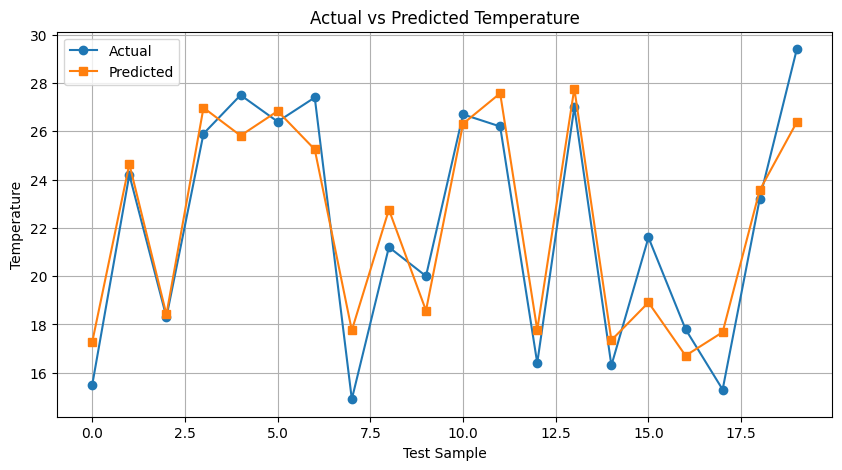

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual,
    label="Actual",
    marker='o'
)

plt.plot(
    predictions,
    label="Predicted",
    marker='s'
)

plt.xlabel("Test Sample")
plt.ylabel("Temperature")

plt.title("Actual vs Predicted Temperature")

plt.legend()

plt.grid(True)

plt.show()